# UrbanFlow AI — Notebook 10: Context-Aware Multi-Scale STGCN

## Objective
Test whether simple time-context features improve traffic forecasting compared with a traffic-only Multi-Scale STGCN baseline.

We compare:
1. **Traffic-only baseline:** traffic history only.
2. **Direct context concatenation:** concatenate five context features to each node's traffic input.
3. **Context-gated model:** use a learned context-dependent sigmoid gate to modulate the traffic representation.

## Experimental contract
- Dataset: METR-LA, 207 sensors, 5-minute sampling.
- Input history: 12 steps (60 minutes).
- Forecast horizon: 3 steps (15 minutes).
- Time features: hour sine/cosine, day-of-week sine/cosine, weekend indicator.
- Context features are aligned to the historical input window only; no future calendar values are fed to the model.
- Compare MAE, RMSE, and MAPE on the same held-out test split.
- This notebook retrains the models. Results can differ from previously recorded runs if seeds, architecture, training settings, checkpoint, or preprocessing differ.


In [53]:
from pathlib import Path
import json, pickle, math, random, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
INPUT_STEPS = 12
OUTPUT_STEPS = 3
NUM_NODES = 207
INPUT_CHANNELS = 1
HIDDEN_CHANNELS = 32
DROPOUT = 0.2
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 5.0
PATIENCE = 5

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Drive mount skipped (not running in Google Colab).")

PROJECT_ROOT = Path("/content/drive/MyDrive/urbanAi")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "METR-LA"
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "METR-LA"
OUTPUT_DIR = Path("/content/experiments/context_aware_multiscale")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert (PROCESSED_DIR / "train.npz").exists(), f"Missing processed data: {PROCESSED_DIR}"
assert (PROCESSED_DIR / "val.npz").exists(), f"Missing validation split: {PROCESSED_DIR}"
assert (PROCESSED_DIR / "test.npz").exists(), f"Missing test split: {PROCESSED_DIR}"
print("Processed data:", PROCESSED_DIR)


Device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processed data: /content/drive/MyDrive/urbanAi/data/processed/METR-LA


## 1. Load data, scaler, and graph adjacency

In [54]:
def load_split(name):
    path = PROCESSED_DIR / f"{name}.npz"
    with np.load(path) as z:
        print(name, "keys:", z.files)
        X = z["X"].astype(np.float32)
        Y = z["Y"].astype(np.float32)
    assert X.ndim == 4 and X.shape[1:] == (INPUT_STEPS, NUM_NODES, 1), X.shape
    assert Y.ndim == 4 and Y.shape[1:] == (OUTPUT_STEPS, NUM_NODES, 1), Y.shape
    assert len(X) == len(Y)
    return X, Y

X_train, Y_train = load_split("train")
X_val, Y_val = load_split("val")
X_test, Y_test = load_split("test")
print("Shapes:", X_train.shape, Y_train.shape, X_val.shape, Y_val.shape, X_test.shape, Y_test.shape)

with np.load(PROCESSED_DIR / "scaler.npz") as s:
    print("Scaler keys:", s.files)
    scaler_mean = s["mean"].astype(np.float32).reshape(-1)
    scaler_std = s["std"].astype(np.float32).reshape(-1)
assert scaler_mean.shape == (NUM_NODES,) and scaler_std.shape == (NUM_NODES,)
assert np.all(scaler_std > 0)

def inverse_scale(x):
    return x * scaler_std.reshape(1, 1, NUM_NODES, 1) + scaler_mean.reshape(1, 1, NUM_NODES, 1)

adj_path = PROCESSED_DIR / "adj_METR-LA.pkl"
assert adj_path.exists(), f"Adjacency not found: {adj_path}"
with open(adj_path, "rb") as f:
    adj_raw = pickle.load(f, encoding="latin1")
A_np = np.asarray(adj_raw[-1] if isinstance(adj_raw, (tuple, list)) else adj_raw, dtype=np.float32)
assert A_np.shape == (NUM_NODES, NUM_NODES), A_np.shape
row_sum = A_np.sum(axis=1, keepdims=True)
if np.any(row_sum <= 0):
    raise ValueError("Adjacency has zero-degree rows; check graph construction.")
A_np = A_np / row_sum
A = torch.tensor(A_np, dtype=torch.float32, device=DEVICE)
print("Adjacency:", A.shape)


train keys: ['X', 'Y']
val keys: ['X', 'Y']
test keys: ['X', 'Y']
Shapes: (23976, 12, 207, 1) (23976, 3, 207, 1) (3413, 12, 207, 1) (3413, 3, 207, 1) (6841, 12, 207, 1) (6841, 3, 207, 1)
Scaler keys: ['mean', 'std']
Adjacency: torch.Size([207, 207])


## 2. Recreate Multi-Scale STGCN building blocks

The implementation below is self-contained to avoid a dependency on `src`. The graph convolution uses the normalized adjacency matrix. Keep this architecture aligned with the version used for the baseline comparison.


In [55]:
class MultiScaleTemporalConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernels=(3, 5), dropout=0.2):
        super().__init__()
        if not kernels:
            raise ValueError("kernels must not be empty")
        branch_channels = [out_channels // len(kernels)] * len(kernels)
        for i in range(out_channels % len(kernels)):
            branch_channels[i] += 1
        self.branches = nn.ModuleList([
            nn.Conv2d(
                in_channels, branch_channels[i],
                kernel_size=(k, 1), padding=(k // 2, 0)
            )
            for i, k in enumerate(kernels)
        ])
        self.norm = nn.BatchNorm2d(out_channels)
        self.activation = nn.GELU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = torch.cat([branch(x) for branch in self.branches], dim=1)
        return self.dropout(self.activation(self.norm(x)))

class GraphConvolution(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.linear = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels))

    def forward(self, x, adjacency):
        # x: (batch, channels, time, nodes); A: (nodes, nodes)
        x = torch.einsum("bc tn,nm->bc tm", x, adjacency) if False else torch.einsum("bctn,nm->bctm", x, adjacency)
        x = self.linear(x)
        return x + self.bias.view(1, -1, 1, 1)

class MultiScaleSTGCNBlock(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernels=(3, 5), dropout=0.2):
        super().__init__()
        self.temporal1 = MultiScaleTemporalConv(in_channels, hidden_channels, kernels, dropout)
        self.graph = GraphConvolution(hidden_channels, hidden_channels)
        self.temporal2 = MultiScaleTemporalConv(hidden_channels, hidden_channels, kernels, dropout)
        self.residual = nn.Conv2d(in_channels, hidden_channels, kernel_size=1) if in_channels != hidden_channels else nn.Identity()
        self.norm = nn.BatchNorm2d(hidden_channels)

    def forward(self, x, adjacency):
        residual = self.residual(x)
        x = self.temporal1(x)
        x = torch.relu(self.graph(x, adjacency))
        x = self.temporal2(x)
        return torch.relu(self.norm(x + residual))

class MultiScaleSTGCN(nn.Module):
    def __init__(self, input_steps=12, output_steps=3, input_channels=1,
                 hidden_channels=32, kernels=(3, 5), dropout=0.2):
        super().__init__()
        self.block1 = MultiScaleSTGCNBlock(input_channels, hidden_channels, kernels, dropout)
        self.block2 = MultiScaleSTGCNBlock(hidden_channels, hidden_channels, kernels, dropout)
        self.head = nn.Sequential(
            nn.Conv2d(hidden_channels, hidden_channels, kernel_size=1),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv2d(hidden_channels, output_steps, kernel_size=1)
        )

    def forward(self, x, adjacency):
        # input (B, T, N, C) -> (B, C, T, N)
        x = x.permute(0, 3, 1, 2)
        x = self.block1(x, adjacency)
        x = self.block2(x, adjacency)
        # forecast using final input representation, output (B, H, N, 1)
        x = x[:, :, -1:, :]
        x = self.head(x).squeeze(2)
        return x.permute(0, 1, 2).unsqueeze(-1)

class DirectContextSTGCN(nn.Module):
    def __init__(self, context_features=5, **kwargs):
        super().__init__()
        self.model = MultiScaleSTGCN(input_channels=1 + context_features, **kwargs)
        self.context_features = context_features

    def forward(self, traffic, context, adjacency):
        # traffic: B,T,N,1; context: B,T,F
        ctx = context.unsqueeze(2).expand(-1, -1, traffic.shape[2], -1)
        x = torch.cat([traffic, ctx], dim=-1)
        return self.model(x, adjacency)

class ContextGatedSTGCN(nn.Module):
    def __init__(self, context_features=5, input_steps=12, output_steps=3,
                 hidden_channels=32, kernels=(3, 5), dropout=0.2):
        super().__init__()
        self.block1 = MultiScaleSTGCNBlock(1, hidden_channels, kernels, dropout)
        self.context_gate = nn.Sequential(
            nn.Linear(context_features, hidden_channels),
            nn.Sigmoid()
        )
        self.block2 = MultiScaleSTGCNBlock(hidden_channels, hidden_channels, kernels, dropout)
        self.head = nn.Sequential(
            nn.Conv2d(hidden_channels, hidden_channels, kernel_size=1),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv2d(hidden_channels, output_steps, kernel_size=1)
        )

    def forward(self, traffic, context, adjacency):
        x = traffic.permute(0, 3, 1, 2)
        x = self.block1(x, adjacency)
        # Context gate is computed per historical time step and broadcast across nodes.
        gate = self.context_gate(context).permute(0, 2, 1).unsqueeze(-1)
        x = x * (1.0 + gate)
        x = self.block2(x, adjacency)
        x = x[:, :, -1:, :]
        x = self.head(x).squeeze(2)
        return x.unsqueeze(-1)


## 3. Build time-context features aligned to input windows

Expected context shape is `(samples, 12, 5)`. We use sine/cosine encodings to avoid discontinuities at hour/day boundaries. **Important:** The processed arrays alone may not include timestamps. This cell first looks for timestamp arrays in each split; if absent, it tries to reconstruct timestamps from the raw METR-LA HDF5 file and the same window indices. If timestamps cannot be aligned reliably, stop rather than inventing time labels.


In [56]:
def discover_raw_h5():
    candidates = [
        RAW_DIR / "METR-LA.h5",
        PROJECT_ROOT / "data" / "raw" / "METR-LA" / "METR-LA.h5",
        Path("/content/drive/MyDrive/urbanAi/data/raw/METR-LA/METR-LA.h5"),
    ]
    for path in candidates:
        if path.exists():
            return path
    # Fall back to searching within the project's data tree.
    data_root = PROJECT_ROOT / "data"
    if data_root.exists():
        matches = list(data_root.rglob("METR-LA.h5"))
        if matches:
            return matches[0]
    return None

def load_raw_timestamps():
    h5_path = discover_raw_h5()
    if h5_path is None:
        print("Could not find METR-LA.h5. Checked:")
        print(" -", RAW_DIR / "METR-LA.h5")
        print(" -", PROJECT_ROOT / "data" / "raw" / "METR-LA" / "METR-LA.h5")
        return None

    print("Raw HDF5 found:", h5_path)
    try:
        import pandas as pd
        with pd.HDFStore(h5_path, mode="r") as store:
            keys = store.keys()
        print("HDF5 keys:", keys)

        # Standard METR-LA files are usually stored as a DataFrame with a DatetimeIndex.
        for key in keys:
            try:
                frame = pd.read_hdf(h5_path, key=key)
                if isinstance(frame.index, pd.DatetimeIndex):
                    print("Using timestamp index from key:", key)
                    return pd.DatetimeIndex(frame.index)
                # Only accept the index if it parses cleanly into timestamps and
                # looks like the original 5-minute METR-LA timeline.
                parsed = pd.to_datetime(frame.index, errors="coerce")
                if len(parsed) and not parsed.isna().any():
                    diffs = pd.Series(parsed).diff().dropna()
                    if len(diffs) and (diffs == pd.Timedelta(minutes=5)).mean() > 0.95:
                        print("Parsed timestamp index from key:", key)
                        return pd.DatetimeIndex(parsed)
            except Exception as e:
                print(f"Could not read HDF5 key {key}: {e}")
    except Exception as e:
        print("Could not inspect raw HDF5:", repr(e))
    return None

timestamps = load_raw_timestamps()
if timestamps is None:
    raise RuntimeError(
        "Could not obtain a reliable DatetimeIndex from METR-LA.h5. "
        "Check the printed path and HDF5 keys. Do not invent timestamps."
    )

# IMPORTANT: preprocessing created windows independently within each chronological split.
# Therefore, each split's raw timeline length is sample_count + INPUT_STEPS + OUTPUT_STEPS - 1.
# This preserves the split boundaries and matches the observed sample counts, rather than
# pretending all windows were made continuously across split boundaries.
split_sample_counts = [len(X_train), len(X_val), len(X_test)]
window_overhead = INPUT_STEPS + OUTPUT_STEPS - 1
split_raw_lengths = [n + window_overhead for n in split_sample_counts]
expected_raw_total = sum(split_raw_lengths)

print("Raw timestamps:", len(timestamps))
print("Split sample counts:", split_sample_counts)
print("Expected raw rows for independently windowed splits:", expected_raw_total)

if len(timestamps) != expected_raw_total:
    raise ValueError(
        f"Raw timeline has {len(timestamps)} rows, but split-local windowing implies "
        f"{expected_raw_total} rows. This suggests preprocessing used a different split/window "
        "convention. Check Notebook 02 before continuing; do not force alignment."
    )

def make_context_for_split(split_timestamps, n_samples):
    # For sample i, the 12 input positions are split_timestamps[i:i+INPUT_STEPS].
    contexts = []
    for i in range(n_samples):
        ts = split_timestamps[i:i + INPUT_STEPS]
        if len(ts) != INPUT_STEPS:
            raise ValueError("Timestamp window has unexpected length.")
        hour = ts.hour.to_numpy() + ts.minute.to_numpy() / 60.0
        dow = ts.dayofweek.to_numpy()
        feat = np.stack([
            np.sin(2 * np.pi * hour / 24.0),
            np.cos(2 * np.pi * hour / 24.0),
            np.sin(2 * np.pi * dow / 7.0),
            np.cos(2 * np.pi * dow / 7.0),
            (dow >= 5).astype(np.float32),
        ], axis=-1)
        contexts.append(feat.astype(np.float32))
    return np.stack(contexts, axis=0)

offset = 0
raw_splits = []
for raw_len in split_raw_lengths:
    raw_splits.append(timestamps[offset:offset + raw_len])
    offset += raw_len

C_train = make_context_for_split(raw_splits[0], len(X_train))
C_val = make_context_for_split(raw_splits[1], len(X_val))
C_test = make_context_for_split(raw_splits[2], len(X_test))

assert C_train.shape == (len(X_train), INPUT_STEPS, 5), C_train.shape
assert C_val.shape == (len(X_val), INPUT_STEPS, 5), C_val.shape
assert C_test.shape == (len(X_test), INPUT_STEPS, 5), C_test.shape
print("Context shapes:", C_train.shape, C_val.shape, C_test.shape)
print("Context feature order: hour_sin, hour_cos, day_sin, day_cos, is_weekend")
print("Context timestamps aligned to split-local historical input windows.")


Raw HDF5 found: /content/drive/MyDrive/urbanAi/data/processed/METR-LA/METR-LA.h5
HDF5 keys: ['/df']
Using timestamp index from key: /df
Raw timestamps: 34272
Split sample counts: [23976, 3413, 6841]
Expected raw rows for independently windowed splits: 34272
Context shapes: (23976, 12, 5) (3413, 12, 5) (6841, 12, 5)
Context feature order: hour_sin, hour_cos, day_sin, day_cos, is_weekend
Context timestamps aligned to split-local historical input windows.


## 4. Training and evaluation utilities

In [57]:
def calculate_metrics(y_true, y_pred, epsilon=1e-5):
    err = y_true - y_pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    mask = np.abs(y_true) > epsilon
    mape = np.mean(np.abs(err[mask] / y_true[mask])) * 100 if mask.any() else np.nan
    return {"MAE": float(mae), "RMSE": float(rmse), "MAPE": float(mape)}

def to_original(y):
    return inverse_scale(y)

def make_loader(X, Y, C=None, shuffle=False):
    xt = torch.tensor(X, dtype=torch.float32)
    yt = torch.tensor(Y, dtype=torch.float32)
    if C is None:
        ds = torch.utils.data.TensorDataset(xt, yt)
    else:
        ct = torch.tensor(C, dtype=torch.float32)
        ds = torch.utils.data.TensorDataset(xt, ct, yt)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=False)

def run_epoch(model, loader, optimizer=None, mode="traffic"):
    training = optimizer is not None
    model.train(training)
    total_loss, total_n = 0.0, 0
    criterion = nn.MSELoss()
    for batch in loader:
        if mode == "traffic":
            xb, yb = batch
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb, A)
        else:
            xb, cb, yb = batch
            xb, cb, yb = xb.to(DEVICE), cb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb, cb, A)
        loss = criterion(pred, yb)
        if training:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
        total_loss += loss.item() * len(xb)
        total_n += len(xb)
    return total_loss / total_n

def train_model(model, train_loader, val_loader, mode, model_name):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    best_val = float("inf")
    best_state = None
    best_epoch = 0
    stale = 0
    history = []
    for epoch in range(1, EPOCHS + 1):
        train_loss = run_epoch(model, train_loader, optimizer, mode)
        val_loss = run_epoch(model, val_loader, None, mode)
        history.append({"epoch": epoch, "train_mse": train_loss, "val_mse": val_loss})
        print(f"{model_name} | epoch {epoch:02d} | train MSE {train_loss:.6f} | val MSE {val_loss:.6f}")
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                print("Early stopping.")
                break
    model.load_state_dict(best_state)
    model.eval()
    with open(OUTPUT_DIR / f"{model_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)
    torch.save(
        {"model_state_dict": model.state_dict(), "best_epoch": best_epoch, "best_val_mse": best_val},
        OUTPUT_DIR / f"{model_name}_best.pt"
    )
    return model, best_epoch, best_val, history

def predict_model(model, X, C=None, mode="traffic"):
    model.eval()
    preds = []
    with torch.no_grad():
        for start in range(0, len(X), BATCH_SIZE):
            xb = torch.tensor(X[start:start+BATCH_SIZE], dtype=torch.float32, device=DEVICE)
            if mode == "traffic":
                p = model(xb, A)
            else:
                cb = torch.tensor(C[start:start+BATCH_SIZE], dtype=torch.float32, device=DEVICE)
                p = model(xb, cb, A)
            preds.append(p.cpu().numpy())
    return np.concatenate(preds, axis=0)


## 5. Train traffic-only baseline

In [58]:
train_loader = make_loader(X_train, Y_train, shuffle=True)
val_loader = make_loader(X_val, Y_val)

traffic_model = MultiScaleSTGCN(
    input_steps=INPUT_STEPS, output_steps=OUTPUT_STEPS, input_channels=1,
    hidden_channels=HIDDEN_CHANNELS, kernels=(3, 5), dropout=DROPOUT
).to(DEVICE)
traffic_model, traffic_best_epoch, traffic_best_val, _ = train_model(
    traffic_model, train_loader, val_loader, "traffic", "traffic_only"
)
traffic_pred_scaled = predict_model(traffic_model, X_test, mode="traffic")
traffic_pred_original = inverse_scale(traffic_pred_scaled)
Y_test_original = inverse_scale(Y_test)
traffic_metrics = calculate_metrics(Y_test_original, traffic_pred_original)
print("Traffic-only test metrics:", traffic_metrics)


traffic_only | epoch 01 | train MSE 0.233613 | val MSE 0.184924
traffic_only | epoch 02 | train MSE 0.192573 | val MSE 0.177439
traffic_only | epoch 03 | train MSE 0.186902 | val MSE 0.175058
traffic_only | epoch 04 | train MSE 0.184694 | val MSE 0.174404
traffic_only | epoch 05 | train MSE 0.183509 | val MSE 0.177121
traffic_only | epoch 06 | train MSE 0.182304 | val MSE 0.174763
traffic_only | epoch 07 | train MSE 0.181172 | val MSE 0.173211
traffic_only | epoch 08 | train MSE 0.180947 | val MSE 0.172103
traffic_only | epoch 09 | train MSE 0.180739 | val MSE 0.175034
traffic_only | epoch 10 | train MSE 0.180017 | val MSE 0.173057
traffic_only | epoch 11 | train MSE 0.178991 | val MSE 0.181285
traffic_only | epoch 12 | train MSE 0.179442 | val MSE 0.172706
traffic_only | epoch 13 | train MSE 0.178826 | val MSE 0.172088
traffic_only | epoch 14 | train MSE 0.178172 | val MSE 0.171733
traffic_only | epoch 15 | train MSE 0.178349 | val MSE 0.172155
traffic_only | epoch 16 | train MSE 0.17

## 6. Train direct context concatenation model

In [59]:
direct_train_loader = make_loader(X_train, Y_train, C_train, shuffle=True)
direct_val_loader = make_loader(X_val, Y_val, C_val)

direct_model = DirectContextSTGCN(
    context_features=5, input_steps=INPUT_STEPS, output_steps=OUTPUT_STEPS,
    hidden_channels=HIDDEN_CHANNELS, kernels=(3, 5), dropout=DROPOUT
).to(DEVICE)
direct_model, direct_best_epoch, direct_best_val, _ = train_model(
    direct_model, direct_train_loader, direct_val_loader, "context", "direct_context"
)
direct_pred_scaled = predict_model(direct_model, X_test, C_test, mode="context")
direct_pred_original = inverse_scale(direct_pred_scaled)
direct_metrics = calculate_metrics(Y_test_original, direct_pred_original)
print("Direct-context test metrics:", direct_metrics)


direct_context | epoch 01 | train MSE 0.266998 | val MSE 0.181433
direct_context | epoch 02 | train MSE 0.195242 | val MSE 0.184206
direct_context | epoch 03 | train MSE 0.187570 | val MSE 0.175685
direct_context | epoch 04 | train MSE 0.184898 | val MSE 0.177886
direct_context | epoch 05 | train MSE 0.182460 | val MSE 0.175064
direct_context | epoch 06 | train MSE 0.181376 | val MSE 0.176614
direct_context | epoch 07 | train MSE 0.180190 | val MSE 0.181536
direct_context | epoch 08 | train MSE 0.179740 | val MSE 0.175951
direct_context | epoch 09 | train MSE 0.178867 | val MSE 0.176786
direct_context | epoch 10 | train MSE 0.176744 | val MSE 0.177102
Early stopping.
Direct-context test metrics: {'MAE': 3.8149516582489014, 'RMSE': 8.26021671295166, 'MAPE': 8.302120208740234}


## 7. Train context-gated model

In [60]:
gated_model = ContextGatedSTGCN(
    context_features=5, input_steps=INPUT_STEPS, output_steps=OUTPUT_STEPS,
    hidden_channels=HIDDEN_CHANNELS, kernels=(3, 5), dropout=DROPOUT
).to(DEVICE)
gated_model, gated_best_epoch, gated_best_val, _ = train_model(
    gated_model, direct_train_loader, direct_val_loader, "context", "context_gated"
)
gated_pred_scaled = predict_model(gated_model, X_test, C_test, mode="context")
gated_pred_original = inverse_scale(gated_pred_scaled)
gated_metrics = calculate_metrics(Y_test_original, gated_pred_original)
print("Context-gated test metrics:", gated_metrics)


context_gated | epoch 01 | train MSE 0.246644 | val MSE 0.175874
context_gated | epoch 02 | train MSE 0.195419 | val MSE 0.174079
context_gated | epoch 03 | train MSE 0.190291 | val MSE 0.175355
context_gated | epoch 04 | train MSE 0.186967 | val MSE 0.172498
context_gated | epoch 05 | train MSE 0.185225 | val MSE 0.172902
context_gated | epoch 06 | train MSE 0.183169 | val MSE 0.176251
context_gated | epoch 07 | train MSE 0.182118 | val MSE 0.172077
context_gated | epoch 08 | train MSE 0.181372 | val MSE 0.173211
context_gated | epoch 09 | train MSE 0.180730 | val MSE 0.173633
context_gated | epoch 10 | train MSE 0.181086 | val MSE 0.174945
context_gated | epoch 11 | train MSE 0.179663 | val MSE 0.172386
context_gated | epoch 12 | train MSE 0.179991 | val MSE 0.173854
Early stopping.
Context-gated test metrics: {'MAE': 3.825490713119507, 'RMSE': 8.198816299438477, 'MAPE': 8.414031982421875}


## 8. Compare models and calculate relative changes

In [61]:
comparison_rows = []
for name, best_epoch, best_val, metric_dict in [
    ("traffic_only", traffic_best_epoch, traffic_best_val, traffic_metrics),
    ("direct_context", direct_best_epoch, direct_best_val, direct_metrics),
    ("context_gated", gated_best_epoch, gated_best_val, gated_metrics),
]:
    comparison_rows.append({
        "model": name,
        "best_epoch": int(best_epoch),
        "best_validation_mse": float(best_val),
        **metric_dict
    })
comparison_df = pd.DataFrame(comparison_rows)
baseline_row = comparison_df.loc[comparison_df["model"] == "traffic_only"].iloc[0]
for metric in ["MAE", "RMSE", "MAPE"]:
    comparison_df[f"{metric}_change_pct_vs_traffic_only"] = (
        (comparison_df[metric] - baseline_row[metric]) / baseline_row[metric] * 100
    )
display(comparison_df.round(6))
comparison_df.to_csv(OUTPUT_DIR / "context_aware_model_comparison.csv", index=False)


,model,best_epoch,best_validation_mse,MAE,RMSE,MAPE,MAE_change_pct_vs_traffic_only,RMSE_change_pct_vs_traffic_only,MAPE_change_pct_vs_traffic_only
0,traffic_only,14,0.171733,3.699081,8.201908,8.007024,0.000000,0.000000,0.000000
1,direct_context,5,0.175064,3.814952,8.260217,8.302120,3.132406,0.710915,3.685469
2,context_gated,7,0.172077,3.825491,8.198816,8.414032,3.417316,-0.037696,5.083139


## 9. Horizon-wise comparison

In [62]:
horizon_rows = []
for name, pred in [
    ("traffic_only", traffic_pred_original),
    ("direct_context", direct_pred_original),
    ("context_gated", gated_pred_original),
]:
    for h in range(OUTPUT_STEPS):
        horizon_rows.append({
            "model": name,
            "horizon_minutes": (h + 1) * 5,
            **calculate_metrics(Y_test_original[:, h], pred[:, h])
        })
horizon_df = pd.DataFrame(horizon_rows)
display(horizon_df.round(6))
horizon_df.to_csv(OUTPUT_DIR / "context_aware_horizon_comparison.csv", index=False)


,model,horizon_minutes,MAE,RMSE,MAPE
0,traffic_only,5,2.939237,6.585872,6.612726
1,traffic_only,10,3.763536,8.285911,8.102718
2,traffic_only,15,4.394475,9.475437,9.305621
3,direct_context,5,3.130576,6.653603,6.868182
4,direct_context,10,3.836615,8.352452,8.395827
5,direct_context,15,4.477665,9.521541,9.642373
6,context_gated,5,3.107415,6.601618,6.943130
7,context_gated,10,3.886852,8.283808,8.534015
8,context_gated,15,4.482207,9.458278,9.764979


## 10. Plot overall model comparison

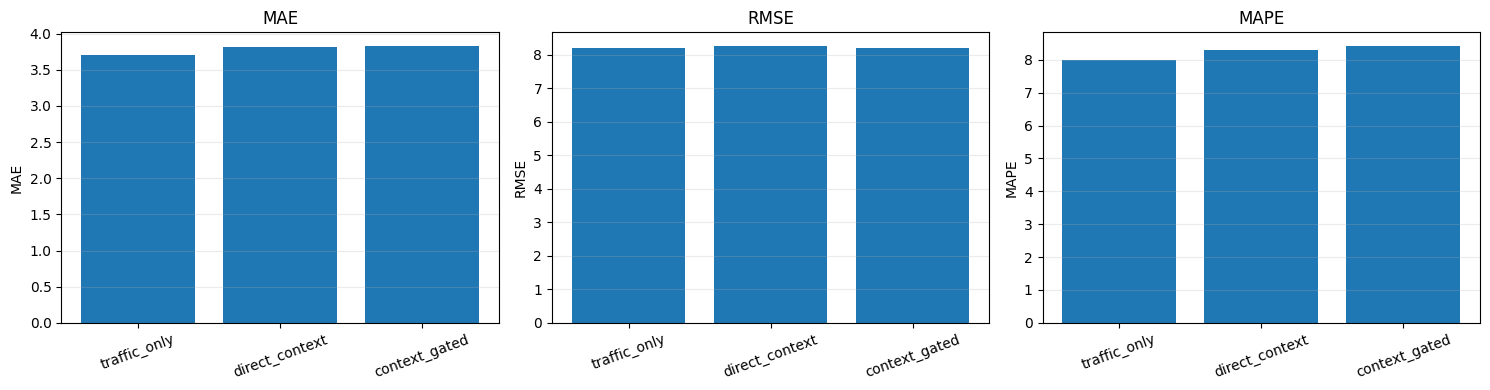

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE"]):
    ax.bar(comparison_df["model"], comparison_df[metric])
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 11. Save predictions and metadata

In [64]:
pred_dir = OUTPUT_DIR / "predictions"
pred_dir.mkdir(parents=True, exist_ok=True)
np.save(pred_dir / "traffic_only.npy", traffic_pred_original.astype(np.float32))
np.save(pred_dir / "direct_context.npy", direct_pred_original.astype(np.float32))
np.save(pred_dir / "context_gated.npy", gated_pred_original.astype(np.float32))
np.save(pred_dir / "test_targets.npy", Y_test_original.astype(np.float32))

metadata = {
    "dataset": "METR-LA",
    "input_steps": INPUT_STEPS,
    "output_steps": OUTPUT_STEPS,
    "num_nodes": NUM_NODES,
    "context_features": ["hour_sin", "hour_cos", "day_sin", "day_cos", "is_weekend"],
    "context_aligned_to_input_window_only": True,
    "seed": SEED,
    "epochs_max": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "hidden_channels": HIDDEN_CHANNELS,
    "kernels": [3, 5],
    "dropout": DROPOUT,
    "warning": "Freshly retrained comparison; results may differ from earlier project runs."
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved outputs under:", OUTPUT_DIR)


Saved outputs under: /content/experiments/context_aware_multiscale


## Interpretation notes

- Compare each context model against `traffic_only` on the same test split.
- Negative change percentages indicate improvement; positive percentages indicate worse error.
- Do not claim context features improve all metrics unless the table supports that claim.
- This notebook reconstructs and retrains the experiment. It is not an exact recovery of the missing original notebook.
- **Timestamp alignment is critical.** The context features must correspond to each sample's actual historical input timestamps. If preprocessing uses a different split/windowing convention, update the timestamp mapping from saved sample indices before trusting the results.
